In [8]:
#Import MNIST dataset
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame = False)

In [ ]:
# Separate data and target and print their shapes
X, y = mnist.data, mnist.target
print(X)
print(X.shape)
print(y)
print(y.shape)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(70000, 784)
['5' '0' '4' ... '4' '5' '6']
(70000,)


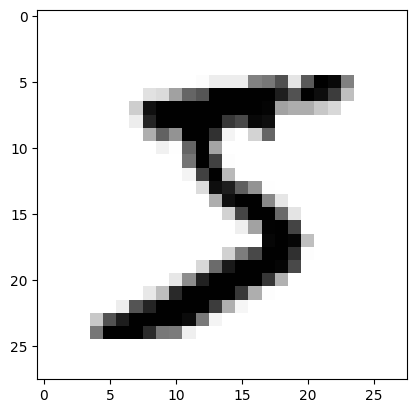

5


In [ ]:
# Plot a digit
import matplotlib.pyplot as plt

def plot_digit(image_data):
    image = image_data.reshape(28,28)
    plt.imshow(image, cmap = "binary")

some_digit = X[0]
plot_digit(some_digit)
plt.show()
print(y[0])

In [ ]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [ ]:
# Train a binary classifier to detect the digit 5
y_train_5 = (y_train == '5')
y_test_5 = (y_test == '5')


# Train a SGDClassifier
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state = 42)
sgd_clf.fit(X_train, y_train_5)

sgd_clf.predict([some_digit ])


array([ True])

In [ ]:
# Evaluate the classifier using cross-validation
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf, X_train, y_train_5, cv = 3, scoring = "accuracy")

array([0.95035, 0.96035, 0.9604 ])

In [ ]:
# Dummy Classifier
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(any(dummy_clf.predict(X_train)))

False


In [ ]:
# Evaluate the Dummy Classifier using cross-validation
cross_val_score(dummy_clf, X_train, y_train_5, cv = 3, scoring = "accuracy")

array([0.90965, 0.90965, 0.90965])

In [ ]:
# Implementing StratifiedKFold cross-validation manually
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits=3)  # add shuffle=True if the dataset is
                                       # not already shuffled
for train_index, test_index in skfolds.split(X_train, y_train_5):
    clone_clf = clone(sgd_clf)
    
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]
    X_test_fold = X_train[test_index]
    y_test_fold = y_train_5[test_index]

    clone_clf.fit(X_train_folds, y_train_folds)

    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    print(n_correct / len(y_pred))



0.95035
0.96035
0.9604


In [ ]:
# Confusion Matrix
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv = 3)

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_5, y_train_pred)
print(cm)

[[53892   687]
 [ 1891  3530]]


In [ ]:
# Perfect classifier confusion matrix
y_train_perfect_predictions = y_train_5
confusion_matrix(y_train_5, y_train_perfect_predictions)

array([[54579,     0],
       [    0,  5421]])

In [ ]:
# Precision, Recall and F1 Score
from sklearn.metrics import precision_score, recall_score, f1_score
print(precision_score(y_train_5, y_train_pred))
print(recall_score(y_train_5, y_train_pred))
print(f1_score(y_train_5, y_train_pred))


0.8370879772350012
0.6511713705958311
0.7325171197343847


In [ ]:
# Decision scores
y_scores = sgd_clf.decision_function([some_digit])
print(y_scores)

# Make predictions based on a decision threshold
threshold = 0
y_some_digit_pred = (y_scores>threshold)
print(y_some_digit_pred)

[2164.22030239]
[ True]


In [ ]:
# Change the decision threshold
y_scores = sgd_clf.decision_function([some_digit])
print(y_scores)


# Change the decision threshold
threshold = 3000
y_some_digit_pred = (y_scores>threshold)
print(y_some_digit_pred)

[2164.22030239]
[False]


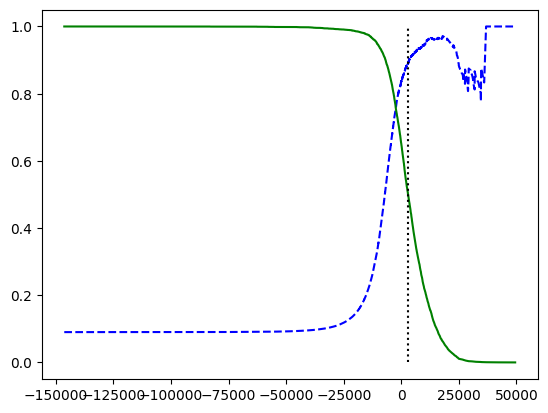

In [ ]:
# Precision-Recall Tradeoff using decision function
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv = 3,
                             method = "decision_function")


# Plotting Precision and Recall vs Decision Threshold
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

plt.plot(thresholds, precisions[:-1], "b--", label = "Precision")
plt.plot(thresholds, recalls[:-1], "g-", label = "Recall")
plt.vlines(threshold, 0,1, "k", "dotted", label = "Threshold")
plt.xlabel("Decision Threshold")
plt.title("Precision-Recall Tradeoff")
plt.legend()
plt.show()



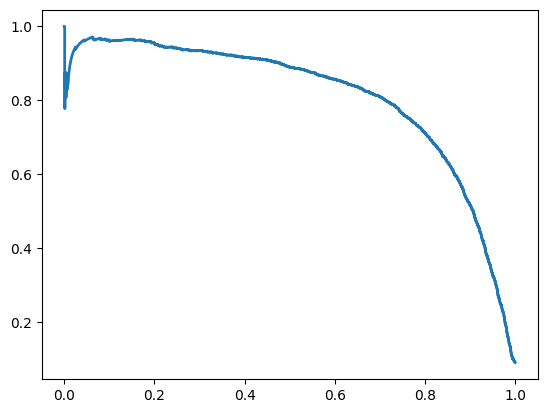

In [ ]:
# Plotting Precision vs Recall
plt.plot(recalls, precisions, linewidth = 2, label = "Precision/Recall curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision vs Recall")
plt.legend()
plt.show()

In [ ]:
# Find the decision threshold for 90% precision by indexing
idx_for_90_precision = (precisions >= 0.90).argmax()
threshold_for_90_precision = thresholds[idx_for_90_precision]
threshold_for_90_precision

np.float64(3370.0194991441826)

In [ ]:
# Make predictions using the threshold for 90% precision
y_train_pred_90 = (y_scores >= threshold_for_90_precision)
print(precision_score(y_train_5, y_train_pred_90))

# Recall at 90% precision
recall_at_90 = recall_score(y_train_5, y_train_pred_90)
print(recall_at_90)

0.9000345901072293
0.4799852425751706


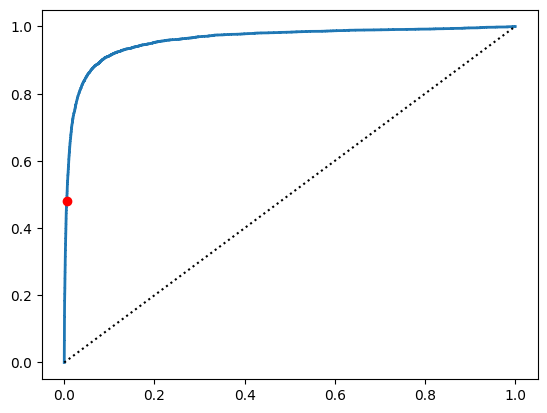

0.9604938554008616


In [ ]:
# ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

# Find the threshold for 90% corresponding TPR and FPR
idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
tpr_90, fpr_90 = tpr[idx_for_threshold_at_90], fpr[idx_for_threshold_at_90]

plt.plot(fpr,tpr,linewidth=2, label = "ROC curve")
plt.plot([0,1],[0,1],"k:", label = "Random classifier's ROC curve")
plt.plot([fpr_90], [tpr_90], "ro", label = "Threshold for 90% precision")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print(roc_auc_score(y_train_5, y_scores))

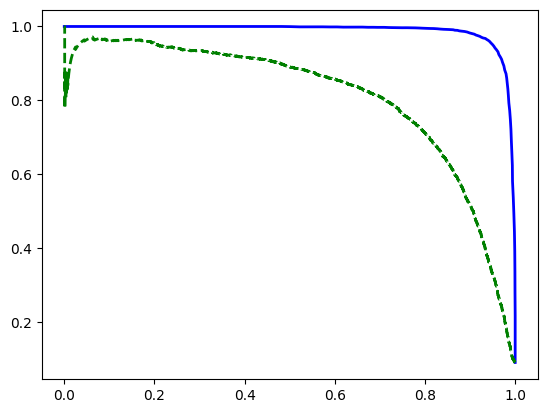

0.9270445185330457
0.9983296721818179
0.8719793396052389
0.9895331798199707


In [ ]:
#Random Forest Classifier with predict_proba method to get probabilities instead of decision scores
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state = 42)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv = 3,
                                    method = "predict_proba")

y_scores_forest = y_probas_forest[:, 1]  # score = proba of positive class
precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve(
    y_train_5, y_scores_forest)

plt.plot(recalls_forest, precisions_forest, "b-", label = "Random Forest", linewidth = 2)
plt.plot(recalls, precisions, "g--", label = "SGD", linewidth = 2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision vs Recall")
plt.legend()
plt.show()

# Evaluate the Random Forest Classifier using F1 Score, ROC AUC Score, Recall and Precision
y_train_pred_forest = y_probas_forest[:,1] >= 0.5
print(f1_score(y_train_5, y_train_pred_forest))
print(roc_auc_score(y_train_5, y_scores_forest))
print(recall_score(y_train_5, y_train_pred_forest))
print(precision_score(y_train_5, y_train_pred_forest))



In [ ]:
# Multiclass Classification using SVM
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])
print(svm_clf.predict([some_digit]))

# Get decision scores for all classes
some_digit_scores = svm_clf.decision_function([some_digit])
print(some_digit_scores.round(2))

# Pick the class with the highest score
class_id = some_digit_scores.argmax()
print(class_id)

['5']
[[ 3.79  0.73  6.06  8.3  -0.29  9.3   1.75  2.77  7.21  4.82]]
5


In [ ]:
# Print all class labels and the predicted class label
print(svm_clf.classes_)
print(svm_clf.classes_[class_id])

['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']
5


In [ ]:
#Forcedly OvR classification
from sklearn.multiclass import OneVsRestClassifier

ovr_clf = OneVsRestClassifier(SVC(random_state=42))
ovr_clf.fit(X_train[:2000], y_train[:2000])
print(ovr_clf.predict([some_digit]))
print(len(ovr_clf.estimators_))

['5']
10


In [ ]:
# Multiclass Classification using SGDClassifier
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train)
print(sgd_clf.predict([some_digit]))
#incorrect prediction


['3']


In [ ]:
# Get decision scores for all classes
print(sgd_clf.decision_function([some_digit]).round())
print(cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy"))

[[-31893. -19048.  -9531.   1824. -22320.  -1386. -26189. -16148.  -4604.
  -12051.]]
[0.87745 0.85835 0.8698 ]


In [ ]:
#Improving accuracy by Feature Scaling
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype(np.float64))
print(cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring="accuracy"))

/opt/anaconda3/envs/torch/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/anaconda3/envs/torch/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/anaconda3/envs/torch/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


[0.89835 0.8902  0.90095]


/opt/anaconda3/envs/torch/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/anaconda3/envs/torch/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/anaconda3/envs/torch/lib/python3.11/site-packages/sklearn/linear_model/_stochastic_gradient.py:733: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


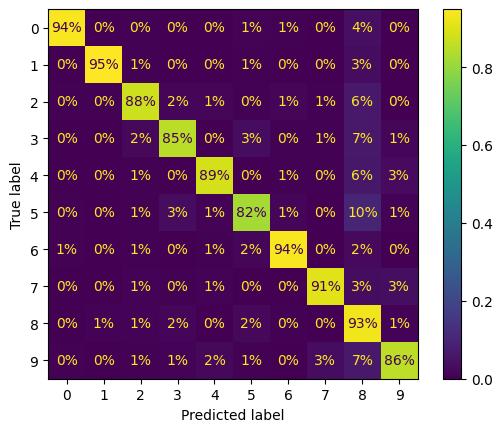

In [ ]:
#Can not do Confusion Matrix for multiclass directly, need to use map
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred  = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, 
                                        normalize='true', 
                                        values_format=".0%")
plt.show()


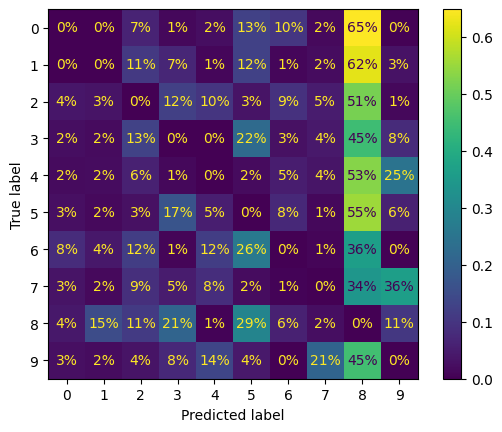

In [ ]:
# Plotting the errors in Confusion Matrix, zeroing the correct predictions
sample_weight = (y_train_pred != y_train)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, 
                                        sample_weight=sample_weight,
                                        normalize='true',
                                        values_format=".0%")
plt.show()

In [ ]:
# Analyzing the types of errors made by the classifier
cl_a, cl_b = '3', '5'
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]
[...] 

[Ellipsis]

In [ ]:
# Multilabel Classification
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train >= '7')
y_train_odd = (y_train.astype(np.int8) % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)
print(knn_clf.predict([some_digit]))

[[False  True]]


In [ ]:
#Evaluate the multilabel classifier using F1 score
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3)
f1_score(y_multilabel, y_train_knn_pred, average="macro")

0.9764102655606048

In [ ]:
# Multioutput Classification with ClassifierChain
from sklearn.multioutput import ClassifierChain

chain_clf = ClassifierChain(SVC(), cv = 3, random_state=42)
chain_clf.fit(X_train[:2000], y_multilabel[:2000])
print(chain_clf.predict([some_digit]))

[[0. 1.]]


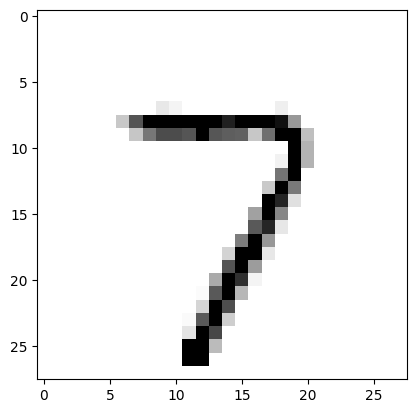

In [ ]:
#Multioutput Denoising example
rng = np.random.default_rng(seed = 42)
noise_train = rng.integers(0,100, (len(X_train), 784))
X_train_mod = X_train + noise_train
noise_test = rng.integers(0,100, (len(X_test), 784))
X_test_mod = X_test + noise_test

y_train_mod = X_train #target
y_test_mod = X_test

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[0]])
plot_digit(clean_digit)
plt.show()

In [ ]:
#1st exercise
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype(np.float64))
X_test_scaled = scaler.transform(X_test.astype(np.float64))

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn_clf = KNeighborsClassifier()

param_grid = [{'n_neighbors': [3,4,5], 
               'weights': ['uniform', 'distance'],}]

grid_search = GridSearchCV(knn_clf, param_grid, cv=3, scoring='accuracy', 
                           return_train_score=True)

grid_search.fit(X_train_scaled, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)

final_model = grid_search.best_estimator_

test_accuracy = final_model.score(X_test_scaled, y_test)
print("Test set accuracy: ", test_accuracy)






{'n_neighbors': 4, 'weights': 'distance'}
0.9437666666666668
Test set accuracy:  0.9489
